In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score

# Data and features
train=pd.read_csv("MLProject2026/data/case1/train1.csv")
test=pd.read_csv("MLProject2026/data/case1/test1.csv")
for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]
    df["deltaP"]=df["outlet_pressure_bar"]-df["inlet_pressure_bar"]

train= train[["n","P","deltaP", "Q"]]
test= test[["n","P","deltaP", "Q"]]

In [2]:
def make_features(df):
    features = pd.DataFrame()
    for i in range(2):
        for j in range(4):
            for k in range (4):
                if i == 0 and j == 0 and k==0:
                    continue
                features["n" + str(j) + "P" + str(k)+ "deltaP"+ str(i)] = df["n"] ** j * df["P"] ** k * df["deltaP"] ** i
    return features

X_train, y_train = make_features(train), train["Q"]
X_test, y_test = make_features(test), test["Q"]

In [ ]:
all_cols = list(X_train.columns)
n_cols = len(all_cols)

all_subsets = [[]]
for col in all_cols:
    new_subsets = []
    for subset in all_subsets:
        new_subsets.append(subset + [col])
    all_subsets = all_subsets + new_subsets
all_subsets = all_subsets[1:]

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=30)

results = []
for subset in all_subsets:
    scores = cross_val_score(LinearRegression(), X_train[subset], y_train,
                             cv=cv, scoring="neg_mean_squared_error")
    e = -scores
    results.append({"n_terms": len(subset), "features": tuple(subset),
                    "mse": e.mean(), "se": e.std(ddof=1) / np.sqrt(len(e))})
results = pd.DataFrame(results)

In [8]:
results.sort_values("mse")

,n_terms,features,mse,se
6,3,"(n, P, deltaP)",12.192435,0.797782
5,2,"(P, deltaP)",20.130007,0.689996
4,2,"(n, deltaP)",34.991711,1.238502
2,2,"(n, P)",88.123316,1.974420
1,1,"(P,)",100.152153,2.288870
0,1,"(n,)",132.518247,4.362363
3,1,"(deltaP,)",171.359433,7.318371


In [13]:
model=LinearRegression().fit(X_train,y_train)
y_pred=model.predict(X_test)
r2_score(y_test, y_pred)
model.coef_

array([ 8.94570755e+00,  2.15044302e-02, -3.62896334e+01])

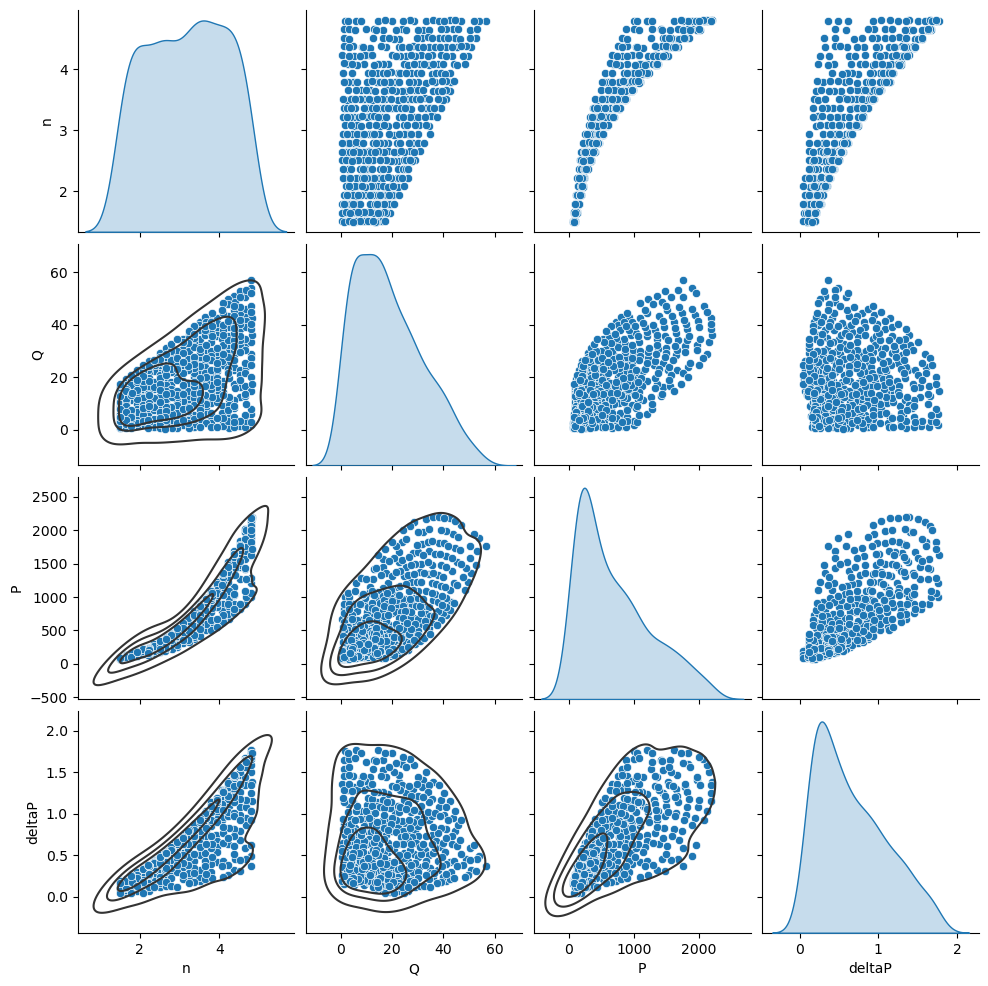

In [17]:
import seaborn as sns

g =sns.pairplot(train[["n", "Q", "P", "deltaP"]], diag_kind="kde")
g.map_lower(sns.kdeplot, levels=4, color=".2")
plt.show()




     k       mse        se
0  0.0  5.561605  0.456726
1  0.5  3.674919  0.332451
2  1.0  2.460717  0.232132
3  1.5  1.349037  0.101808
4  2.0  0.544239  0.044184
5  2.5  1.139469  0.041158
6  3.0  2.055906  0.123157
7  3.5  3.988567  0.340282
8  4.0  7.141731  0.743582
   n_terms        mse        se                                                                        features
0        1  57.107017  4.937861                                                                       (n*xP^2,)
1        2   4.077792  0.169529                                                             (n*xP^2, n*xP^2*xD)
2        3   0.860619  0.051822                                                                 (n, n*xD, n*xP)
3        4   0.796820  0.043075                                                  (n, n*xD^2, n*xD^3, n*xP^2*xD)
4        5   0.691467  0.048095                                           (n, n*xD, n*xD^3, n*xP*xD, n*xP*xD^2)
5        6   0.548035  0.045439                           

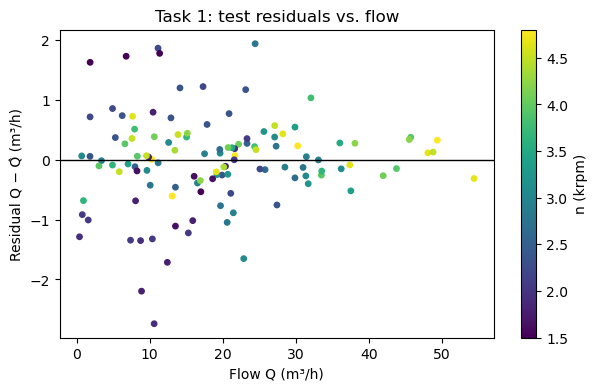

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

# ---------- Data ----------
train = pd.read_csv("MLProject2026/data/case1/train1.csv")
test = pd.read_csv("MLProject2026/data/case1/test1.csv")
for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]
    df["deltaP"] = df["outlet_pressure_bar"] - df["inlet_pressure_bar"]

# ---------- Constant power loss P0 from the Task 0 model ----------
X0 = pd.DataFrame({"n3Q0": train["n"] ** 3,
                   "n2Q1": train["n"] ** 2 * train["Q"],
                   "n1Q2": train["n"] * train["Q"] ** 2,
                   "n0Q3": train["Q"] ** 3})
task0_model = LinearRegression().fit(X0, train["P"])
P0 = task0_model.intercept_

for df in (train, test):
    df["xP"] = (df["P"] - P0) / df["n"] ** 3

# ---------- Features ----------
def term_name(a, b):
    name = "n"
    if a > 0:
        name += "*xP" + ("^" + str(a) if a > 1 else "")
    if b > 0:
        name += "*xD" + ("^" + str(b) if b > 1 else "")
    return name

def make_features(df):
    features = pd.DataFrame()
    for a in range(4):
        for b in range(4):
            if a + b <= 3:
                features[term_name(a, b)] = df["n"] * df["xP"] ** a * df["xD"] ** b
    return features

y_train = train["Q"]
y_test = test["Q"]
cv = KFold(n_splits=5, shuffle=True, random_state=30)

def cv_mse(X, y, cv):
    scores = cross_val_score(LinearRegression(), X, y, cv=cv,
                             scoring="neg_mean_squared_error")
    return -scores                      # the 5 fold MSEs

# ---------- Step 1: choose the pressure exponent k ----------
k_results = []
for k in [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4]:
    for df in (train, test):
        df["xD"] = df["deltaP"] / df["n"] ** k
    e = cv_mse(make_features(train), y_train, cv)
    k_results.append({"k": k, "mse": e.mean(),
                      "se": e.std(ddof=1) / np.sqrt(len(e))})
k_results = pd.DataFrame(k_results)
print(k_results)

best_k = k_results.sort_values("mse").iloc[0]["k"]
for df in (train, test):
    df["xD"] = df["deltaP"] / df["n"] ** best_k

# ---------- Step 2: exhaustive subset search ----------
X_train = make_features(train)
X_test = make_features(test)
all_cols = list(X_train.columns)
n_cols = len(all_cols)

all_subsets = [[]]
for col in all_cols:
    new_subsets = []
    for subset in all_subsets:
        new_subsets.append(subset + [col])
    all_subsets = all_subsets + new_subsets
all_subsets = all_subsets[1:]

results = []
for subset in all_subsets:
    e = cv_mse(X_train[subset], y_train, cv)
    results.append({"n_terms": len(subset), "features": tuple(subset),
                    "mse": e.mean(), "se": e.std(ddof=1) / np.sqrt(len(e))})
results = pd.DataFrame(results)

# ---------- Step 3: best per size and 1-SE rule ----------
best_rows = []
for t in range(1, n_cols + 1):
    models_with_t_terms = results[results["n_terms"] == t]
    best_rows.append(models_with_t_terms.sort_values("mse").iloc[0])
best = pd.DataFrame(best_rows).reset_index(drop=True)

lowest = best.sort_values("mse").iloc[0]
threshold = lowest["mse"] + lowest["se"]
for i in range(len(best)):
    if best.iloc[i]["mse"] <= threshold:
        chosen = best.iloc[i]
        break

print(best[["n_terms", "mse", "se", "features"]].to_string())
print("Chosen:", chosen["n_terms"], "terms:", chosen["features"])

# ---------- Step 4: baseline and final model on the test set ----------
base_cols = ["n", "P", "deltaP"]
baseline = LinearRegression().fit(train[base_cols], y_train)
base_mse = np.mean((y_test - baseline.predict(test[base_cols])) ** 2)

chosen_cols = list(chosen["features"])
final_model = LinearRegression().fit(X_train[chosen_cols], y_train)
y_pred = final_model.predict(X_test[chosen_cols])
residuals = y_test.to_numpy() - y_pred
test_mse = np.mean(residuals ** 2)

print("Baseline test MSE:", base_mse)
print("Final test MSE:   ", test_mse)

# ---------- Step 5: print the final formula ----------
formula = f"Q = {final_model.intercept_:.4f}"
for name, coef in zip(chosen_cols, final_model.coef_):
    sign = "-" if coef < 0 else "+"
    formula += f" {sign} {abs(coef):.4f}*{name}"
print(formula)

# ---------- Step 6: residuals vs flow ----------
fig, ax = plt.subplots(figsize=(7, 4))
sc = ax.scatter(test["Q"], residuals, c=test["n"], cmap="viridis", s=15)
fig.colorbar(sc, label="n (krpm)")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Flow Q (m³/h)")
ax.set_ylabel("Residual Q − Q̂ (m³/h)")
ax.set_title("Task 1: test residuals vs. flow")
plt.show()